# Clinical Information Extraction from ICU Admission Diagnoses with a Local LLM

**Key results**
- **299 / 300** model outputs were valid structured JSON (99.7%)
- **86%** body-system and **82%** procedure agreement with reference labels on a random sample of 100 phrases (Cohen's κ 0.83 and 0.56)
- Labels assigned to **37,078 admissions** (62.9%) by processing only the 300 most frequent phrases
- Error analysis traced most disagreements to **four prompt and schema gaps**, not to the model itself

## Overview
Admission diagnoses in MIMIC-III are short free text: abbreviated, inconsistent and often holding more than one condition (`CAD\CABG /SDA`, `S/P FALL;TELEMETRY`). In this form they cannot be grouped, counted or used as model features.

This notebook converts the free-text `AdmitDiagnosis` field into two structured fields:

| Field | Values |
|---|---|
| `body_system` | Heart, Lungs, Brain, Gut and Liver, Kidney, Infection, Cancer, Injury, Metabolic, Newborn, Other |
| `procedure_mentioned` | Yes, No, Unclear |

**Approach**
- Llama 3.1 8B run locally through Ollama; the extraction step sends no data to external services
- Few-shot prompt with a closed label set, JSON output and temperature 0
- Raw responses kept; unusable answers recorded as extraction errors instead of being guessed
-  Reference labels for 100 randomly sampled phrases were created by the author following a written annotation guideline, then reviewed with an LLM; disagreements were resolved by the author.

**Pipeline**
```
AdmitDiagnosis → normalise text → unique phrases → Llama (JSON) → validate
→ map to admissions → reference labels → agreement, baseline and error analysis
```

## Data
`hadm_id` and `AdmitDiagnosis` from the aggregated MIMIC-III dataset `mimic3c.csv` ([Kaggle](https://www.kaggle.com/datasets/drscarlat/mimic3c)), saved as `admit_diagnosis.csv`. Data files are not included in the repository under the MIMIC data use agreement. Setup instructions are in the README.

### 1. Setup and Environment Check
Confirms the local model responds before any batch work starts.

In [1]:
import os
import re
import json
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ollama

%matplotlib inline

# Folders for saved charts and result files
os.makedirs("images", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# The local model used for extraction
MODEL_NAME = "llama3.1:8b"

# Send a one-word test message to check Ollama is running
reply = ollama.chat(model=MODEL_NAME, messages=[{"role": "user", "content": "Reply with the word OK."}])
print("Ollama is working. Model reply:", reply["message"]["content"])

Ollama is working. Model reply: OK


### 2. Load Data

In [2]:
# One row per hospital admission: the admission ID and the free-text diagnosis
df = pd.read_csv("admit_diagnosis.csv")

print("Rows:", len(df))
df.head(10)

Rows: 58976


,hadm_id,AdmitDiagnosis
0,100001,DIABETIC KETOACIDOSIS
1,100003,UPPER GI BLEED
2,100006,COPD FLARE
3,100007,BOWEL OBSTRUCTION
4,100009,CORONARY ARTERY DISEASE
5,100010,RENAL MASS LEFT/SDA
6,100011,MOTOR VEHICLE ACCIDENT WITH UNSPECIFIED INJURIES
7,100012,CORONARY ARTERY DISEASE
8,100014,RIGHT SHOULDER ADHESIVE CAPSULITIS/SDA
9,100016,PNEUMONIA


## Exploratory Analysis of the Text

### 3. Vocabulary Size and Frequency
How many different phrases exist, and how often each one repeats.

In [3]:
# How many diagnoses are missing, and how many different phrases there are
print("Missing values:", df["AdmitDiagnosis"].isna().sum())
print("Different phrases:", df["AdmitDiagnosis"].nunique())

# The 15 most common phrases
df["AdmitDiagnosis"].value_counts().head(15)

Missing values: 25
Different phrases: 15691


AdmitDiagnosis
NEWBORN                                                      7823
PNEUMONIA                                                    1566
SEPSIS                                                       1184
CONGESTIVE HEART FAILURE                                      928
CORONARY ARTERY DISEASE                                       840
CHEST PAIN                                                    778
INTRACRANIAL HEMORRHAGE                                       713
ALTERED MENTAL STATUS                                         712
GASTROINTESTINAL BLEED                                        686
CORONARY ARTERY DISEASE\CORONARY ARTERY BYPASS GRAFT /SDA     583
UPPER GI BLEED                                                580
ABDOMINAL PAIN                                                554
FEVER                                                         510
DIABETIC KETOACIDOSIS                                         462
CORONARY ARTERY DISEASE\CORONARY ARTERY BYPASS GRAFT/SDA     

**Findings**
- 15,691 different phrases for 58,976 admissions, and a highly skewed distribution: `NEWBORN` alone covers 7,823 admissions (13.3%).
- The same condition appears in many forms (`GASTROINTESTINAL BLEED`, `UPPER GI BLEED`, `GI BLEED`), so grouping on raw text would split it apart.

### 4. Abbreviations and Multi-Diagnosis Entries

| Token | Meaning |
|---|---|
| S/P | Status post (prior event) |
| R/O | Rule out (unconfirmed) |
| /SDA | Same day admission (often, not always, elective surgery) |
| CAD / CABG | Coronary artery disease / coronary artery bypass graft |
| GI / CHF | Gastrointestinal / congestive heart failure |
| `\` or `;` | Separator between two diagnoses, or a diagnosis and a procedure |

In [4]:
# Replace missing values with empty text so the searches below work
text = df["AdmitDiagnosis"].fillna("")

# Count rows that contain each special token
print("Rows with a backslash (more than one entry):", text.str.contains("\\", regex=False).sum())
print("Rows with S/P:", text.str.contains("S/P", regex=False).sum())
print("Rows with R/O or RULE OUT:", text.str.contains("R/O|RULE OUT", regex=True).sum())
print("Rows with SDA:", text.str.contains("SDA", regex=False).sum())

# Show 10 random examples
print("\nRandom examples:")
for t in text.sample(10, random_state=1):
    print("  ", t)

Rows with a backslash (more than one entry): 6774
Rows with S/P: 1787
Rows with R/O or RULE OUT: 416
Rows with SDA: 6678

Random examples:
   ELECTROLYTE ABNORMALITIES
   GASTROINTESTINAL BLEED
   INTRACRANIAL HEMORRHAGE
   BILE DUCT STRICTURE/SDA
   S/P CARDIAC ARREST
   CONGESTIVE HEART FAILURE
   NEWBORN
   CONGESTIVE HEART FAILURE
   HYPOTHERMIA
   FEVER


**Findings**
- 6,774 admissions (11.5%) contain a backslash and 6,678 (11.3%) contain `SDA`; `S/P` (1,787) and `R/O` (416) are also common.
- A keyword approach would need explicit handling for every abbreviation, separator and qualifier, which motivates using a language model.

## Text Normalisation

### 5. Normalise Text and Keep Unique Phrases
Each unique phrase is sent to the model once, and the result is copied back to every admission with that phrase.

In [5]:
# Clean the text: fill missing values, trim spaces, upper-case, collapse repeated spaces
df["diagnosis_clean"] = (
    df["AdmitDiagnosis"]
    .fillna("UNKNOWN")
    .str.strip()
    .str.upper()
    .str.replace(r"\s+", " ", regex=True)
)

# Count admissions per phrase, most common first
phrase_counts = df["diagnosis_clean"].value_counts()
unique_phrases = phrase_counts.index.tolist()
print("Unique phrases:", len(unique_phrases))

# Share of admissions covered by the most common phrases
for n in [100, 300, 1000, len(unique_phrases)]:
    covered = phrase_counts.head(n).sum() / len(df) * 100
    print(f"Top {n:>6} phrases cover {covered:5.1f}% of admissions")

Unique phrases: 15614
Top    100 phrases cover  52.6% of admissions
Top    300 phrases cover  62.9% of admissions
Top   1000 phrases cover  71.6% of admissions
Top  15614 phrases cover 100.0% of admissions


**Findings**
- Normalisation reduces 15,691 strings to 15,614 unique phrases.
- The top 300 phrases cover 62.9% of admissions at about 2% of the cost of processing the full vocabulary.

## LLM Extraction

### 6. Label Schema

**`body_system`** (exactly one)

| Label | Includes |
|---|---|
| Heart | chest pain, CAD, heart failure, MI, valve disease |
| Lungs | pneumonia, COPD, respiratory failure |
| Brain | stroke, intracranial bleed, seizure, altered mental status |
| Gut and Liver | GI bleed, pancreatitis, liver failure, abdominal pain |
| Kidney | kidney failure, urinary problems |
| Infection | sepsis, fever, infection not tied to one organ |
| Cancer | tumour, lymphoma, leukaemia |
| Injury | fall, trauma, fracture, overdose |
| Metabolic | DKA, electrolyte disorders, glucose problems |
| Newborn | newborn, prematurity |
| Other | a valid diagnosis outside the categories above |

**`procedure_mentioned`**

| Label | Definition | Example |
|---|---|---|
| Yes | A procedure or operation is named (past or planned) | `CAD\CABG`, `S/P LIVER TRANSPLANT` |
| No | No procedure is named | `PNEUMONIA` |
| Unclear | Only an indirect hint, no procedure named | `ABDOMINAL MASS/SDA` |

`Extraction error` is kept separate from `Other` and marks answers that could not be read or were outside the label set.

In [6]:
# The only answers the model is allowed to give
BODY_SYSTEMS = [
    "Heart", "Lungs", "Brain", "Gut and Liver", "Kidney", "Infection",
    "Cancer", "Injury", "Metabolic", "Newborn", "Other",
]
PROCEDURE_LABELS = ["Yes", "No", "Unclear"]

### 7. Prompt Design
- **Closed label set** with exact spelling, plus definitions of the abbreviations from Section 4
- **Three worked examples** (few-shot); if a line holds two diagnoses, the first one decides the body system
- **JSON-only output** (`format="json"`) at temperature 0, so the same phrase always gets the same answer

In [7]:
# The instruction sent to Llama for every phrase; {diagnosis} is filled in each time
PROMPT_TEMPLATE = r"""You are a clinical coding assistant.
Read one hospital admission diagnosis and return two labels.

1. body_system: choose exactly ONE, spelled exactly as written:
   Heart, Lungs, Brain, Gut and Liver, Kidney, Infection, Cancer, Injury, Metabolic, Newborn, Other
   Use "Gut and Liver" for anything in the stomach, intestines, oesophagus, pancreas, gallbladder or liver (including GI bleeding).

2. procedure_mentioned: choose exactly ONE: Yes, No, Unclear
   Yes = the text names a procedure or operation (past or planned), for example CABG, valve replacement, cath, resection, transplant.
   No = no procedure is named.
   Unclear = only a hint such as /SDA with no procedure named.

Short forms: S/P = status post, R/O = rule out, SDA = same day admission,
CAD = coronary artery disease, CABG = coronary artery bypass graft, GI = gastrointestinal,
CHF = congestive heart failure, MI = myocardial infarction, CVA = stroke, DKA = diabetic ketoacidosis.
A backslash separates two diagnoses. Use the FIRST diagnosis for body_system.

Examples:
Diagnosis: CORONARY ARTERY DISEASE\CORONARY ARTERY BYPASS GRAFT /SDA
{{"body_system": "Heart", "procedure_mentioned": "Yes"}}
Diagnosis: PANCREATITIS
{{"body_system": "Gut and Liver", "procedure_mentioned": "No"}}
Diagnosis: S/P FALL
{{"body_system": "Injury", "procedure_mentioned": "No"}}

Answer with JSON only.
Diagnosis: {diagnosis}
"""

### 8. Inspect Raw Model Output
Looking at the raw answers first separates formatting problems (spelling, key names) from wrong labels.

In [8]:
def ask_llm(diagnosis):
    # Put the phrase into the prompt and send it to the local model
    response = ollama.chat(
        model=MODEL_NAME,
        messages=[{"role": "user", "content": PROMPT_TEMPLATE.format(diagnosis=diagnosis)}],
        format="json",                # force a JSON answer
        options={"temperature": 0},   # same input, same output
    )
    # Return the model's text answer
    return response["message"]["content"]


# Try four phrases and print the raw answers
for phrase in ["UPPER GI BLEED", "CONGESTIVE HEART FAILURE", "CORONARY ARTERY DISEASE\\CATH", "SEPSIS"]:
    print(f"{phrase:35} →  {ask_llm(phrase)}")

UPPER GI BLEED                      →  {
  "body_system": "Gut and Liver",
  "procedure_mentioned": "No"
}
CONGESTIVE HEART FAILURE            →  {
  "body_system": "Heart",
  "procedure_mentioned": "No"
}
CORONARY ARTERY DISEASE\CATH        →  {
  "body_system": "Heart",
  "procedure_mentioned": "Yes"
}
SEPSIS                              →  {
  "body_system": "Infection",
  "procedure_mentioned": "No"
}


**Finding:** all four answers are valid JSON with the expected keys and correct labels, including the abbreviation `GI` and the stacked entry `...\CATH`.

### 9. Extraction and Schema Validation
Each answer is parsed, matched to the label set (ignoring case and common synonyms) and checked. Anything that still does not fit becomes `Extraction error` with a `status` code; nothing is silently changed to `Other`.

In [9]:
# Common alternative words the model might use, mapped to our official labels
BODY_SYNONYMS = {
    "gut and liver": "Gut and Liver", "gut & liver": "Gut and Liver", "gut": "Gut and Liver",
    "liver": "Gut and Liver", "gastrointestinal": "Gut and Liver", "gi": "Gut and Liver",
    "digestive": "Gut and Liver", "hepatic": "Gut and Liver",
    "cardiac": "Heart", "cardiovascular": "Heart",
    "respiratory": "Lungs", "pulmonary": "Lungs", "lung": "Lungs",
    "neurological": "Brain", "neuro": "Brain", "nervous system": "Brain",
    "renal": "Kidney", "kidneys": "Kidney",
    "oncology": "Cancer", "trauma": "Injury",
    "neonatal": "Newborn", "endocrine": "Metabolic",
}

In [10]:
def clean_body(value):
    # Return the official body-system label, or None if the answer does not fit
    if not isinstance(value, str):
        return None
    value = value.strip()

    # Exact label, ignoring upper/lower case
    for label in BODY_SYSTEMS:
        if value.lower() == label.lower():
            return label

    # Otherwise try the synonym list
    return BODY_SYNONYMS.get(value.lower())


def clean_procedure(value):
    # Return Yes / No / Unclear, or None if the answer does not fit
    if not isinstance(value, str):
        return None
    value = value.strip().capitalize()
    if value in PROCEDURE_LABELS:
        return value
    return None

In [11]:
def extract_labels(diagnosis):
    # Step 1: ask the model and keep its raw answer
    raw = ask_llm(diagnosis)
    row = {"diagnosis_clean": diagnosis, "raw_response": raw}

    # Step 2: read the JSON; if it is broken, record an error and stop
    try:
        result = json.loads(raw)
    except json.JSONDecodeError:
        row["body_system"] = "Extraction error"
        row["procedure_mentioned"] = "Extraction error"
        row["status"] = "json_error"
        return row

    # Step 3: match both answers to the allowed labels
    body = clean_body(result.get("body_system"))
    proc = clean_procedure(result.get("procedure_mentioned"))

    # Step 4: save the labels, or mark them as errors if they did not fit
    row["body_system"] = body if body else "Extraction error"
    row["procedure_mentioned"] = proc if proc else "Extraction error"
    row["status"] = "ok" if (body and proc) else "invalid_label"
    return row


# Quick test on one phrase
extract_labels("UPPER GI BLEED")

{'diagnosis_clean': 'UPPER GI BLEED',
 'raw_response': '{\n  "body_system": "Gut and Liver",\n  "procedure_mentioned": "No"\n}',
 'body_system': 'Gut and Liver',
 'procedure_mentioned': 'No',
 'status': 'ok'}

### 10. Pilot Run (20 Phrases)

In [12]:
# Pick 20 random phrases from the top 300
test_phrases = pd.Series(unique_phrases[:300]).sample(20, random_state=42).tolist()

# Label them and time how long it takes
start = time.time()
test_results = pd.DataFrame([extract_labels(p) for p in test_phrases])
seconds_per_phrase = (time.time() - start) / len(test_phrases)

print(f"Seconds per phrase: {seconds_per_phrase:.2f}")
print(f"Estimated time for 300 phrases: {seconds_per_phrase * 300 / 60:.0f} minutes")
print("Status counts:", test_results["status"].value_counts().to_dict())
test_results[["diagnosis_clean", "body_system", "procedure_mentioned", "status"]]

Seconds per phrase: 9.54
Estimated time for 300 phrases: 48 minutes
Status counts: {'ok': 20}


,diagnosis_clean,body_system,procedure_mentioned,status
0,LUNG CANCER,Lungs,No,ok
1,INTRACEREBRAL HEMORRHAGE,Brain,No,ok
2,BACK PAIN,Injury,No,ok
3,UPPER GI BLEED,Gut and Liver,No,ok
4,CORONARY ARTERY DISEASE\CORONARY ARTERY BYPASS...,Heart,Yes,ok
5,STAB WOUND,Injury,No,ok
6,ETOH INTOXICATION,Metabolic,No,ok
7,COPD EXACERBATION,Lungs,No,ok
8,CHEST PAIN,Heart,No,ok
9,CONGESTIVE HEART FAILURE\CATH,Heart,Yes,ok


**Findings**
- 20/20 answers were valid. Latency is roughly 10 seconds per phrase on CPU (9.7 to 10.8 seconds across runs), about 50 minutes for 300 phrases.
- Two systematic issues are already visible: `;TELEMETRY` (cardiac monitoring) is treated as a procedure, and cancers are assigned to their organ (`LUNG CANCER` → Lungs).

### 11. Extraction on the 300 Most Frequent Phrases
Results are saved every 50 phrases to `outputs/llm_labels.csv`. If the run stops, rerunning this cell continues from the last save, and if all 300 are already saved it finishes immediately.

In [13]:
DEMO_N = 300                          # number of most common phrases to label (None = all)
SAVE_PATH = "outputs/llm_labels.csv"
COLUMNS = ["diagnosis_clean", "body_system", "procedure_mentioned", "status", "raw_response"]

# The phrases to process
if DEMO_N is None:
    phrases_to_run = unique_phrases
else:
    phrases_to_run = unique_phrases[:DEMO_N]

# Load earlier results if they exist
if os.path.exists(SAVE_PATH):
    done = pd.read_csv(SAVE_PATH)
else:
    done = pd.DataFrame(columns=COLUMNS)

# Skip phrases that are already labelled
done_set = set(done["diagnosis_clean"])
remaining = [p for p in phrases_to_run if p not in done_set]
print(f"Already done: {len(done_set)} | Remaining: {len(remaining)}")

new_rows = []
start = time.time()

for i, phrase in enumerate(remaining, start=1):
    # Label one phrase
    new_rows.append(extract_labels(phrase))

    # Every 50 phrases (and at the end), add the new rows and save to disk
    if i % 50 == 0 or i == len(remaining):
        done = pd.concat([done, pd.DataFrame(new_rows)[COLUMNS]], ignore_index=True)
        done.to_csv(SAVE_PATH, index=False)
        new_rows = []
        print(f"Saved {i}/{len(remaining)} phrases  ({(time.time() - start) / 60:.1f} minutes)")

print("Finished. Total labelled phrases:", len(done))

Already done: 300 | Remaining: 0
Finished. Total labelled phrases: 300


### 12. Extraction Error Rate

In [14]:
# Load the saved labels (one row per phrase)
labels = pd.read_csv(SAVE_PATH).drop_duplicates("diagnosis_clean")

# Count valid answers and errors
print(labels["status"].value_counts())
print(f"\nExtraction error rate: {(labels['status'] != 'ok').mean() * 100:.1f}%")

# Show any errors with the model's raw answer
labels[labels["status"] != "ok"][["diagnosis_clean", "raw_response", "status"]]

status
ok               299
invalid_label      1
Name: count, dtype: int64

Extraction error rate: 0.3%


,diagnosis_clean,raw_response,status
278,THROMBOCYTOPENIA,"{\n ""body_system"": ""Blood"",\n ""procedure_men...",invalid_label


**Finding:** 299 of 300 answers (99.7%) were valid. The single failure, `THROMBOCYTOPENIA` → `"Blood"`, is a gap in the label set: the model proposed a category the schema does not offer.

### 13. Map Labels to Admissions

In [15]:
# Copy each phrase's labels to every admission with that phrase
df_labeled = df.merge(
    labels[["diagnosis_clean", "body_system", "procedure_mentioned", "status"]],
    on="diagnosis_clean",
    how="left",
)

# Admissions whose phrase was not in the top 300
for col in ["body_system", "procedure_mentioned", "status"]:
    df_labeled[col] = df_labeled[col].fillna("Not processed")

covered = (df_labeled["status"] != "Not processed").mean() * 100
print(f"Admissions with labels: {covered:.1f}%")

df_labeled.to_csv("outputs/admit_diagnosis_labeled.csv", index=False)
df_labeled[["hadm_id", "AdmitDiagnosis", "body_system", "procedure_mentioned"]].head(10)

Admissions with labels: 62.9%


,hadm_id,AdmitDiagnosis,body_system,procedure_mentioned
0,100001,DIABETIC KETOACIDOSIS,Metabolic,No
1,100003,UPPER GI BLEED,Gut and Liver,No
2,100006,COPD FLARE,Lungs,No
3,100007,BOWEL OBSTRUCTION,Gut and Liver,No
4,100009,CORONARY ARTERY DISEASE,Heart,No
5,100010,RENAL MASS LEFT/SDA,Not processed,Not processed
6,100011,MOTOR VEHICLE ACCIDENT WITH UNSPECIFIED INJURIES,Injury,No
7,100012,CORONARY ARTERY DISEASE,Heart,No
8,100014,RIGHT SHOULDER ADHESIVE CAPSULITIS/SDA,Not processed,Not processed
9,100016,PNEUMONIA,Lungs,No


### 14. Distribution of Extracted Labels

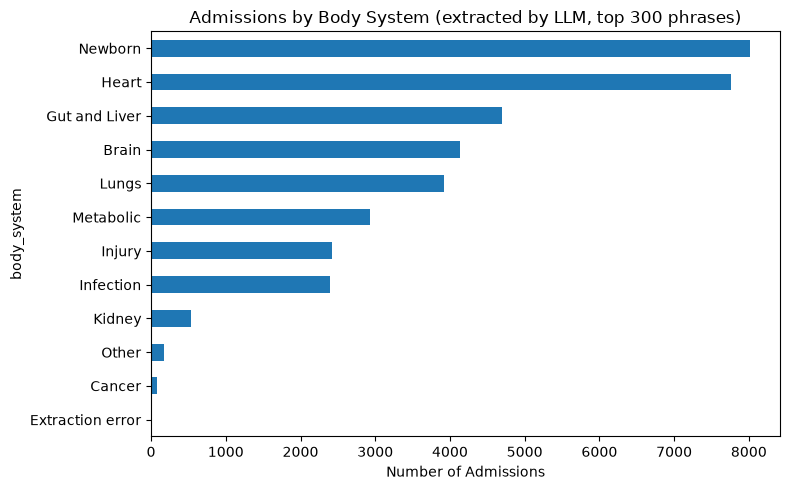

procedure_mentioned
No         33168
Yes         3675
Unclear      235
Name: count, dtype: int64


In [16]:
# Keep only admissions that received labels
labeled_only = df_labeled[df_labeled["status"] != "Not processed"]

# Bar chart of admissions per body system
labeled_only["body_system"].value_counts().sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Admissions by Body System (extracted by LLM, top 300 phrases)")
plt.xlabel("Number of Admissions")
plt.tight_layout()
plt.savefig("images/body_system_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(labeled_only["procedure_mentioned"].value_counts())

**Findings**
- Newborn (21.6%) and Heart (20.9%) dominate, followed by Gut and Liver (12.7%), Brain (11.2%) and Lungs (10.6%). The large Newborn group reflects MIMIC-III's neonatal ICU.
- Cancer is almost empty (85 admissions, 0.2%) because cancers were assigned to their organ.
- `procedure_mentioned`: No 89.5%, Yes 9.9%, Unclear 0.6%.

## Evaluation

A random sample of 100 labelled phrases (`random_state=7`) received reference labels produced with an external LLM, following a written annotation guideline, without access to Llama's predictions, and reviewed by the author. Llama's labels are compared with this reference.

### 15. Reference Label Workbook
`outputs/reference_labels.xlsx` holds each sampled phrase, a plain-English meaning, the reference labels (`ref_body_system`, `ref_procedure`) and the annotation guideline (`Rules` tab).

In [17]:
from openpyxl import load_workbook
from openpyxl.worksheet.datavalidation import DataValidation

REF_PATH = "outputs/reference_labels.xlsx"

# The same 100 random phrases every time (fixed random_state)
sample = labels[["diagnosis_clean"]].sample(100, random_state=7).reset_index(drop=True)
sample["ref_body_system"] = ""
sample["ref_procedure"] = ""

if os.path.exists(REF_PATH):
    print("Reference workbook found:", REF_PATH)
else:
    # Create an empty workbook with dropdown lists for labelling
    sample.to_excel(REF_PATH, index=False)
    wb = load_workbook(REF_PATH)
    ws = wb.active
    dv_body = DataValidation(type="list", formula1='"' + ",".join(BODY_SYSTEMS) + '"', allow_blank=True)
    dv_proc = DataValidation(type="list", formula1='"' + ",".join(PROCEDURE_LABELS) + '"', allow_blank=True)
    ws.add_data_validation(dv_body)
    ws.add_data_validation(dv_proc)
    dv_body.add(f"B2:B{len(sample) + 1}")
    dv_proc.add(f"C2:C{len(sample) + 1}")
    wb.save(REF_PATH)
    print("Created:", REF_PATH)

Reference workbook found: outputs/reference_labels.xlsx


### 16. Agreement Between Llama and the Reference Labels

In [18]:
# Load the reference labels and join Llama's labels to them
ref = pd.read_excel(REF_PATH).dropna(subset=["ref_body_system", "ref_procedure"])
compare = ref.merge(labels, on="diagnosis_clean", how="left")

# True where Llama and the reference agree
compare["body_match"] = compare["body_system"] == compare["ref_body_system"]
compare["procedure_match"] = compare["procedure_mentioned"] == compare["ref_procedure"]

print(f"Phrases compared: {len(compare)}")
print(f"Body system agreement:         {compare['body_match'].mean() * 100:.1f}%")
print(f"Procedure mentioned agreement: {compare['procedure_match'].mean() * 100:.1f}%")
print("(Extraction errors count as disagreements.)")

compare.to_csv("outputs/llm_vs_reference.csv", index=False)

Phrases compared: 100
Body system agreement:         86.0%
Procedure mentioned agreement: 82.0%
(Extraction errors count as disagreements.)


**Confusion matrices.** Rows are the reference label, columns are Llama's label. Numbers on the diagonal are agreements; everything off the diagonal is a disagreement.

In [19]:
# Body system: reference (rows) vs Llama (columns)
pd.crosstab(compare["ref_body_system"], compare["body_system"], rownames=["Reference"], colnames=["Llama"])

Llama,Brain,Extraction error,Gut and Liver,Heart,Infection,Injury,Kidney,Lungs,Metabolic,Newborn
Reference,,,,,,,,,,
Brain,19,0,0,0,0,0,0,0,3,0
Cancer,0,0,1,0,0,0,1,1,0,0
Gut and Liver,0,0,14,0,0,1,0,0,0,0
Heart,1,0,1,28,0,1,0,0,1,0
Infection,0,0,0,0,2,0,0,0,0,0
Injury,0,0,1,0,0,7,0,0,0,0
Kidney,0,0,0,0,0,0,1,0,0,0
Lungs,0,0,0,0,0,0,0,8,0,0
Metabolic,0,0,0,0,0,0,0,0,6,0


In [20]:
# Procedure: reference (rows) vs Llama (columns)
pd.crosstab(compare["ref_procedure"], compare["procedure_mentioned"], rownames=["Reference"], colnames=["Llama"])

Llama,No,Unclear,Yes
Reference,,,
No,67,0,7
Unclear,9,1,2
Yes,0,0,14


In [21]:
# Phrases where Llama and the reference disagree on body system
compare[~compare["body_match"]][["diagnosis_clean", "ref_body_system", "body_system"]]

,diagnosis_clean,ref_body_system,body_system
1,WEAKNESS,Other,Metabolic
11,BLADDER CANCER/SDA,Cancer,Kidney
17,ABDOMINAL AORTIC ANEURYSM,Heart,Gut and Liver
26,LIVER LACERATION,Injury,Gut and Liver
45,INCISIONAL HERNIA/SDA,Gut and Liver,Injury
50,HYPOTENSION,Heart,Metabolic
53,ALTERED MENTAL STATUS;TELEMETRY,Brain,Metabolic
54,THROMBOCYTOPENIA,Other,Extraction error
56,CHANGE IN MENTAL STATUS,Brain,Metabolic
62,CAROTID STENOSIS,Heart,Injury


### 17. Per-Category Metrics and Cohen's Kappa
Precision: of the phrases Llama put in a category, the share that were right. Recall: of the phrases that belong in a category, the share Llama found. Cohen's kappa measures agreement after removing agreement expected by chance (0 = chance level, 1 = perfect).

In [22]:
from sklearn.metrics import classification_report, cohen_kappa_score

print("BODY SYSTEM")
print(classification_report(compare["ref_body_system"], compare["body_system"], zero_division=0))

print("PROCEDURE MENTIONED")
print(classification_report(compare["ref_procedure"], compare["procedure_mentioned"], zero_division=0))

print(f"Cohen's kappa, body system: {cohen_kappa_score(compare['ref_body_system'], compare['body_system']):.2f}")
print(f"Cohen's kappa, procedure:   {cohen_kappa_score(compare['ref_procedure'], compare['procedure_mentioned']):.2f}")

BODY SYSTEM
                  precision    recall  f1-score   support

           Brain       0.95      0.86      0.90        22
          Cancer       0.00      0.00      0.00         3
Extraction error       0.00      0.00      0.00         0
   Gut and Liver       0.82      0.93      0.88        15
           Heart       1.00      0.88      0.93        32
       Infection       1.00      1.00      1.00         2
          Injury       0.78      0.88      0.82         8
          Kidney       0.50      1.00      0.67         1
           Lungs       0.89      1.00      0.94         8
       Metabolic       0.55      1.00      0.71         6
         Newborn       1.00      1.00      1.00         1
           Other       0.00      0.00      0.00         2

        accuracy                           0.86       100
       macro avg       0.62      0.71      0.65       100
    weighted avg       0.85      0.86      0.85       100

PROCEDURE MENTIONED
              precision    recall  f1

**Findings**
- Body system: κ = 0.83 (strong agreement), weighted F1 0.85. Large categories score well (Heart F1 0.93, Lungs 0.94, Brain 0.90). Cancer F1 is 0 (all 3 cancer phrases went to their organ), and Metabolic precision is 0.55 because altered mental status and hypotension were placed there.
- Procedure: κ = 0.56 (moderate). `Yes` recall is 1.00 (no named procedure was missed) but precision is 0.61, and `Unclear` recall is 0.08: the model rarely uses `Unclear`.
- The macro-average F1 (0.65 for body system) is pulled down by categories with only 1 to 3 examples, so per-category results on this sample are indicative rather than precise.

### 18. Admission-Weighted Agreement
Phrase-level agreement treats `PNEUMONIA` (1,566 admissions) and a rare phrase (1 admission) equally. Weighting each phrase by its number of admissions shows agreement from the patient-record point of view.

In [23]:
# Number of admissions for each sampled phrase
compare["admissions"] = compare["diagnosis_clean"].map(phrase_counts)

def weighted_agreement(match_column):
    # Agreement where each phrase counts as many times as it appears in the data
    return (compare[match_column] * compare["admissions"]).sum() / compare["admissions"].sum() * 100

print(f"Admissions represented by the sample: {compare['admissions'].sum():,}")
print(f"Body system  - phrase-level: {compare['body_match'].mean() * 100:.1f}%   admission-weighted: {weighted_agreement('body_match'):.1f}%")
print(f"Procedure    - phrase-level: {compare['procedure_match'].mean() * 100:.1f}%   admission-weighted: {weighted_agreement('procedure_match'):.1f}%")

Admissions represented by the sample: 8,623
Body system  - phrase-level: 86.0%   admission-weighted: 88.8%
Procedure    - phrase-level: 82.0%   admission-weighted: 92.5%


**Finding:** weighted by admissions, agreement rises to 88.8% for body system and 92.5% for procedure (the 100 phrases represent 8,623 admissions). Errors are concentrated in less frequent phrases such as `/SDA` and `;TELEMETRY` variants, so the labels are more reliable at the admission level than the phrase-level figures suggest.

### 19. Keyword-Rule Baseline
A simple rule system written from the same annotation guideline: keyword lists checked in a fixed order (cancer, injury, newborn, then body part), and procedure words such as `CATH` or `BYPASS`.

In [24]:
# Keyword lists taken from the annotation guideline
CANCER_WORDS = ["CANCER", "LYMPHOMA", "LEUKEMIA", "CARCINOMA", " CA/", " CA ", "MELANOMA", "MALIGNAN"]
INJURY_WORDS = ["FALL", "TRAUMA", "FRACTURE", "LACERATION", "STRUCK", "ACCIDENT", "MVA", "OVERDOSE", " OD",
                "ASSAULT", "STAB", "GUN SHOT", "GSW", "INJUR", "BURN"]
NEWBORN_WORDS = ["NEWBORN", "PREMATUR", "HYPERBILIRUBINEMIA"]
SYSTEM_WORDS = {
    "Heart": ["HEART", "CARDIAC", "CARDIO", "CORONARY", "CAD", "ANGINA", "MYOCARDIAL", " MI", "STEMI", "CHF",
              "AORTIC", "MITRAL", "VALVE", "CAROTID", "ANEURYSM", "BRADYCARDIA", "TACHYCARDIA", "SYNCOPE",
              "ATRIAL", "HYPOTENSION", "CHEST PAIN", "DISSECTION"],
    "Lungs": ["PNEUMONIA", "LUNG", "ASTHMA", "COPD", "RESPIRATORY", "PLEURAL", "HEMOTHORAX", "PNEUMOTHORAX",
              "TRACHEA", "PULMONARY", "DYSPNEA", "HYPOXIA", "SHORTNESS OF BREATH"],
    "Brain": ["BRAIN", "STROKE", "CVA", "TIA", "TRANSIENT ISCHEMIC", "INTRACRANIAL", "SUBDURAL", "SUBARACHNOID",
              "SAH", "CEREBR", "MENING", "HYDROCEPHALUS", "SEIZURE", "MENTAL STATUS", "UNRESPONSIVE", "HEAD BLEED"],
    "Gut and Liver": ["LIVER", "HEPATIC", "CIRRHOSIS", "GI ", "GASTRO", "BOWEL", "PANCREA", "CHOLE", "ESOPHAG",
                      "ABDOMINAL", "JAUNDICE", "HERNIA", "DIVERTICUL", "MESENTERIC", "COLITIS", "APPENDIC"],
    "Kidney": ["RENAL", "KIDNEY", "BLADDER", "URINARY", "HEMATURIA"],
    "Infection": ["SEPSIS", "SEPTIC", "ABSCESS", "FEVER", "BACTEREMIA", "CELLULITIS", "INFECTION"],
    "Metabolic": ["DKA", "KETOACIDOSIS", "GLYCEMIA", "KALEMIA", "NATREMIA", "DEHYDRATION", "WITHDRAWAL", "OBESITY"],
}
PROCEDURE_WORDS = ["CATH", "BYPASS", "CABG", "ANGIOPLASTY", "REPLACEMENT", "TRANSPLANT", "ANGIOGRAM", "AVR", "MVR", "RESECTION"]


def has_any(text, words):
    # True if any keyword appears in the text
    padded = " " + text + " "
    return any(word in padded for word in words)


def rule_body_system(diagnosis):
    # Use only the first diagnosis (text before a backslash or semicolon)
    first = re.split(r"[\\;]", diagnosis)[0]

    # Check special categories first, in priority order
    if has_any(first, CANCER_WORDS):
        return "Cancer"
    if has_any(first, INJURY_WORDS):
        return "Injury"
    if has_any(first, NEWBORN_WORDS):
        return "Newborn"

    # Then the body-part keyword lists
    for system, words in SYSTEM_WORDS.items():
        if has_any(first, words):
            return system

    # No keyword matched
    return "Other"


def rule_procedure(diagnosis):
    # A named procedure gives Yes; /SDA alone gives Unclear; otherwise No
    if has_any(diagnosis, PROCEDURE_WORDS):
        return "Yes"
    if "SDA" in diagnosis:
        return "Unclear"
    return "No"

In [25]:
# Apply the rules to the same 100 phrases
compare["rule_body"] = compare["diagnosis_clean"].apply(rule_body_system)
compare["rule_proc"] = compare["diagnosis_clean"].apply(rule_procedure)

results = pd.DataFrame({
    "Method": ["Llama 3.1 8B", "Keyword rules"],
    "Body system agreement (%)": [
        compare["body_match"].mean() * 100,
        (compare["rule_body"] == compare["ref_body_system"]).mean() * 100,
    ],
    "Procedure agreement (%)": [
        compare["procedure_match"].mean() * 100,
        (compare["rule_proc"] == compare["ref_procedure"]).mean() * 100,
    ],
}).round(1)
results

,Method,Body system agreement (%),Procedure agreement (%)
0,Llama 3.1 8B,86.0,82.0
1,Keyword rules,95.0,100.0


In [26]:
# Where the rules go wrong on body system
compare[compare["rule_body"] != compare["ref_body_system"]][["diagnosis_clean", "ref_body_system", "rule_body", "body_system"]]

,diagnosis_clean,ref_body_system,rule_body,body_system
18,UNSTABLE ANGINA;TELEMETRY\CATH,Heart,Injury,Heart
25,CEREBRAL ANEURYSM,Brain,Heart,Brain
34,BRAIN ANEURYSM/SDA,Brain,Heart,Brain
65,CEREBRAL VASCULAR ACCIDENT,Brain,Injury,Brain
80,UNSTABLE ANGINA\CATH,Heart,Injury,Heart


In [27]:
# How well do the rules cover phrases they were not written for?
rare_phrases = unique_phrases[300:]
rare_rules = pd.Series([rule_body_system(p) for p in rare_phrases])
top_rules = pd.Series([rule_body_system(p) for p in unique_phrases[:300]])

print(f"Top 300 phrases with no keyword match:     {(top_rules == 'Other').mean() * 100:.1f}%")
print(f"Remaining {len(rare_phrases):,} phrases with no keyword match: {(rare_rules == 'Other').mean() * 100:.1f}%")

Top 300 phrases with no keyword match:     15.7%
Remaining 15,314 phrases with no keyword match: 33.7%


**Findings**
- On the 100-phrase sample the rules score 95% (body system) and 100% (procedure), above Llama. This is an **optimistic upper bound**: the rules were written directly from the same guideline used for the reference labels, with the sample visible while writing them.
- The 100% procedure score shows that the procedure guideline is essentially a keyword rule. For this field a rule system is the simpler and more reliable tool, and the LLM adds little.
- The rules are brittle where wording varies: `STAB` inside `UNSTABLE ANGINA` → Injury, `ACCIDENT` inside `CEREBRAL VASCULAR ACCIDENT` → Injury, and `CEREBRAL ANEURYSM` → Heart. Llama labelled all of these correctly.
- Generalisation is the main weakness: the rules find no keyword for 15.7% of the top 300 phrases but 33.7% of the 15,314 rarer phrases, where an LLM does not depend on a fixed word list.

## Error Analysis

| Pattern | Disagreements | Example | Cause |
|---|---|---|---|
| `/SDA` with no named procedure not marked Unclear | 11 (procedure) | `LIVER MASS/SDA` → No | Rule competes with the model's own judgement |
| Telemetry treated as a procedure | 6 (procedure) | `PNEUMONIA;TELEMETRY` → Yes | Monitoring not defined in the prompt |
| Cancer assigned to the organ | 3 (body) | `LUNG CANCER/SDA` → Lungs | No precedence rule |
| Blood-vessel conditions misplaced | 3 (body) | `CAROTID STENOSIS` → Injury | No vascular category or rule |
| Altered mental status → Metabolic | 3 (body) | `MENTAL STATUS CHANGES` | Category boundary not defined |
| Other boundary cases and one label-set gap | 5 (body), 1 (procedure) | `THROMBOCYTOPENIA` → "Blood" | Missing category |

**Interpretation:** 26 of the 32 disagreements fall into the first five patterns. The guideline rules for telemetry, cancer precedence and vascular conditions were not in the v1 prompt, so these errors point to prompt and schema gaps that a revised prompt can address, rather than to limits of the model.

# Summary

| Stage | Result |
|---|---|
| Text profiling | 58,976 admissions, 15,614 unique phrases; top 300 cover 62.9% |
| Extraction | Llama 3.1 8B (local), few-shot JSON prompt, about 10 s per phrase on CPU |
| Output validity | 299/300 valid (99.7%) |
| Agreement (n=100) | Body system 86% (κ 0.83), procedure 82% (κ 0.56) |
| Admission-weighted agreement | Body system 88.8%, procedure 92.5% |
| Keyword baseline | 95% / 100% on the sample (optimistic); no keyword match for 33.7% of rare phrases |

## Limitations
- Only the 300 most frequent phrases were processed.
- The reference labels come from an LLM following a written guideline, reviewed by a non-clinician; agreement measures consistency with that guideline, not clinical accuracy.
- The 100-phrase sample is small, so per-category metrics are imprecise for rare categories.
- Admission diagnoses are short; full clinical notes contain far more information.

## Future Work
- Revised prompt (v2) adding the telemetry, `/SDA`, cancer and vascular rules, evaluated on the same reference set
- Clinician review of the reference sample
- Extraction on all 15,614 phrases, with the keyword rules used for `procedure_mentioned` and the LLM for `body_system`
- Application to full clinical notes (MIMIC-III NOTEEVENTS)